In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
#from sklearn.metrics import confusion_matrix, classification_report
from funcoes_ml import *

In [5]:
# Carregando dataset MNIST a partir da OpenML
print("Baixando o dataset MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
print("Finalizou o processo de baixar o dataset MNIST!")

Baixando o dataset MNIST...
Finalizou o processo de baixar o dataset MNIST!


In [6]:
# Separação entre features e target
X, y = mnist.data, mnist.target

In [7]:
# Exploração da dimensionalidade das matrizes
print (f'========>> A matriz X possui {X.shape[0]} amostras, sendo {X.shape[1]} pixels por imagem')
print (f'========>> A matriz y é unidimensional e possui {y.shape[0]} rótulos / targets\n')
print (f'========>> Matriz de pixels de uma amostra:\n\n {X[10000]}')

========>> A matriz X possui 70000 amostras, sendo 784 pixels por imagem
========>> A matriz y é unidimensional e possui 70000 rótulos / targets

========>> Matriz de pixels de uma amostra:

 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0  29 150 195 254 255 254 176 193 150  96   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0  48 166 224 253 253
 234 196 253 253 253 253 233   0   0   0   0   0   0   0   0   0   0   0
   0 

In [8]:
# Verificação da distribuição das classes e balanceamento do dataset
rotulos, freq_abs = np.unique(y, return_counts=True)
freq_perc = np.round(freq_abs / freq_abs.sum() * 100, decimals = 2)
print (f'Rótulos únicos: {rotulos}')
print (f'Frequências absolutas: {freq_abs}')
print (f'Frequências percentuais: {freq_perc}')

Rótulos únicos: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
Frequências absolutas: [6903 7877 6990 7141 6824 6313 6876 7293 6825 6958]
Frequências percentuais: [ 9.86 11.25  9.99 10.2   9.75  9.02  9.82 10.42  9.75  9.94]


In [9]:
# Averiguação dos tipos de dados
print (f'Tipos de dados da matriz X: {X.dtype}')
print (f'Tipos de dados da matriz y: {y.dtype}')

Tipos de dados da matriz X: int64
Tipos de dados da matriz y: object


In [10]:
# Alteração do tipo de dados da matriz de rótulos para inteiro
y = y.astype(np.uint8)

In [11]:
# divisão estratificada dos dados em conjunto de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y, random_state=42)

In [12]:
# escalonamento dos dados
scaler = MinMaxScaler()

X_train_escalonado = scaler.fit_transform(X_train)
X_test_escalonado = scaler.transform(X_test)

In [13]:
''' Cria uma lista de dicionários, no qual cada item é uma família de modelos
    Cada um recebe o nome/tipo do modelo, um dicionário com parâmetros de gridsearch e o modelo base a ser instanciado
'''
modelos_testar = []

modelos_testar.append({
    'nome_modelo':'RandomForest',
    'param_grid': {'n_estimators':[50,150], # número de árvores
                    'max_depth':[10,20]}, # profundidade da árvore
    'modelo_base': RandomForestClassifier(n_jobs=-1, random_state=42)
    })

modelos_testar.append({
    'nome_modelo':'MLP',
    'param_grid': {
        "hidden_layer_sizes": [(64,), (100, 50)], # testa uma camada de 64 layers ocultos e duas camadas de 100 e 50 layers ocultos
        "learning_rate_init": [0.001, 0.01]}, # taxa de aprendizagem inicial. Ela vai sendo alterada dinamicamente durante o treino
    'modelo_base': MLPClassifier(
        activation="relu", # função de ativação dos neurônios. Matematicamente simples e atenua a oscilação
        solver="adam", # otimizador que atualiza os pesos e vieses dinamicamente e individualmente para cada neurônio
       early_stopping=True, # para o treinamento quando ele parar de melhorar. Economiza processamento e tempo
        random_state=42,
        verbose=True)
    })

In [14]:
'''
    A lista de modelos vai ser percorrida e submetida à avaliação de parâmetros
    Os melhores de cada família farão parte de outra lista de modelos que serão treinados em toda a base
'''

melhores_modelos = []
for i in modelos_testar:
    nome_modelo = i['nome_modelo']
    param_grid = i['param_grid']
    modelo_base = i['modelo_base']

    melhor_modelo = procura_melhores_parametros(nome_modelo, modelo_base, param_grid, X_train_escalonado, y_train)
    melhores_modelos.append({'nome_modelo':nome_modelo, 'modelo': melhor_modelo})


Iniciando a busca de parâmetros otimizados do modelo RandomForest...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV 2/3] END .....max_depth=10, n_estimators=50;, score=0.932 total time=   1.7s
[CV 1/3] END .....max_depth=20, n_estimators=50;, score=0.940 total time=   2.3s
[CV 3/3] END .....max_depth=10, n_estimators=50;, score=0.924 total time=   3.9s
[CV 2/3] END .....max_depth=20, n_estimators=50;, score=0.944 total time=   3.7s
[CV 1/3] END .....max_depth=10, n_estimators=50;, score=0.929 total time=   3.4s
[CV 1/3] END ....max_depth=10, n_estimators=150;, score=0.939 total time=   4.7s
[CV 3/3] END ....max_depth=10, n_estimators=150;, score=0.932 total time=   5.6s
[CV 3/3] END .....max_depth=20, n_estimators=50;, score=0.939 total time=   4.4s
[CV 2/3] END ....max_depth=10, n_estimators=150;, score=0.940 total time=   6.5s
[CV 1/3] END ....max_depth=20, n_estimators=150;, score=0.948 total time=   5.0s
[CV 3/3] END ....max_depth=20, n_estimators=150;, score=0.94

In [15]:
'''
Treinamento dos 3 melhores modelos de cada família em toda a base de treino
Serão geradas 3 listas contendo: as métricas de cada modelo, as matrizes de confusão,
e as instâncias dos modelos treinados
'''
resultados_modelos = []
matrizes = []
modelos_treinados = []

for m in melhores_modelos:

    nome_classificador = m['nome_modelo']
    classificador = m['modelo']
    
    resultados_modelo, matriz_confusao, classificador_treinado = treina_modelo(
        nome_classificador, classificador, X_train_escalonado, y_train, X_test_escalonado, y_test)
    
    resultados_modelos.append(resultados_modelo)
    matrizes.append({'classificador':nome_classificador, 'matriz_confusao': matriz_confusao})
    modelos_treinados.append({'modelo': nome_classificador, 'modelo_treinado': classificador_treinado})


Iniciando o treinamento final do modelo RandomForest com toda a base de treino
Treinamento concluído com sucesso em 0.24 minutos!
Calculando predições nos dados de treino
Calculando predições nos dados de teste
Acurácia treino: 0.9993571428571428
Acurácia teste: 0.9668571428571429
Métricas do modelo: 
{'precision': 0.9668476583017888, 'recall': 0.9668571428571429, 'f1-score': 0.9668294476341031, 'support': 14000.0}

Iniciando o treinamento final do modelo MLP com toda a base de treino
Iteration 1, loss = 0.28890145
Validation score: 0.955000
Iteration 2, loss = 0.12710026
Validation score: 0.963036
Iteration 3, loss = 0.10197786
Validation score: 0.964464
Iteration 4, loss = 0.08481426
Validation score: 0.965357
Iteration 5, loss = 0.08016442
Validation score: 0.964107
Iteration 6, loss = 0.05930022
Validation score: 0.964643
Iteration 7, loss = 0.06457182
Validation score: 0.964643
Iteration 8, loss = 0.06093330
Validation score: 0.967500
Iteration 9, loss = 0.05182990
Validation sco

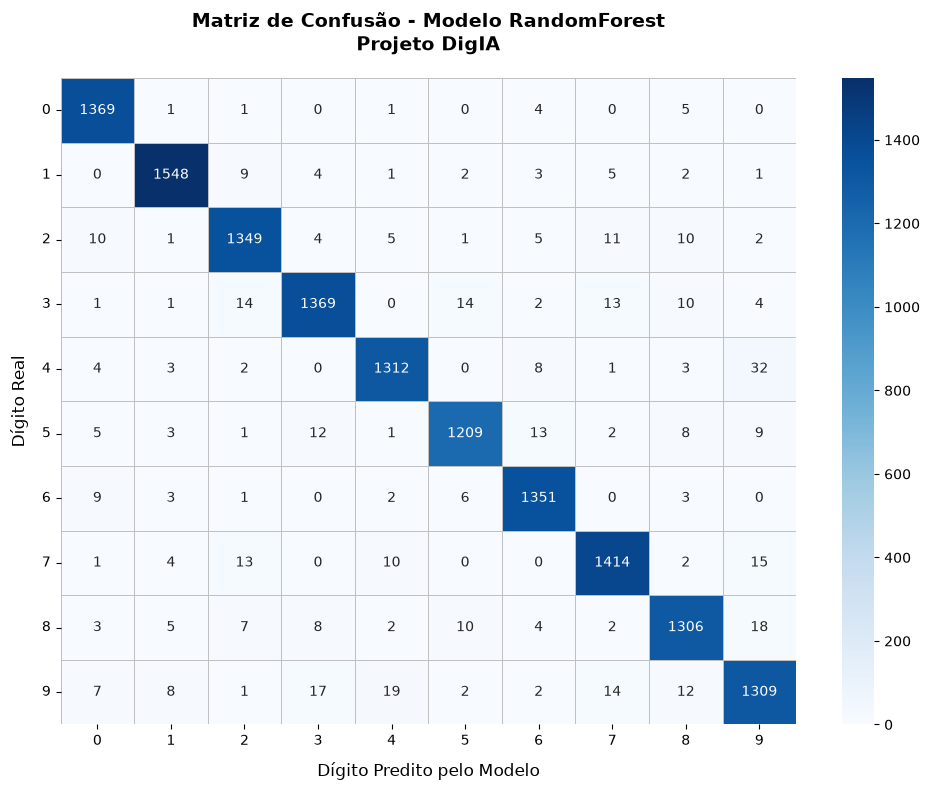

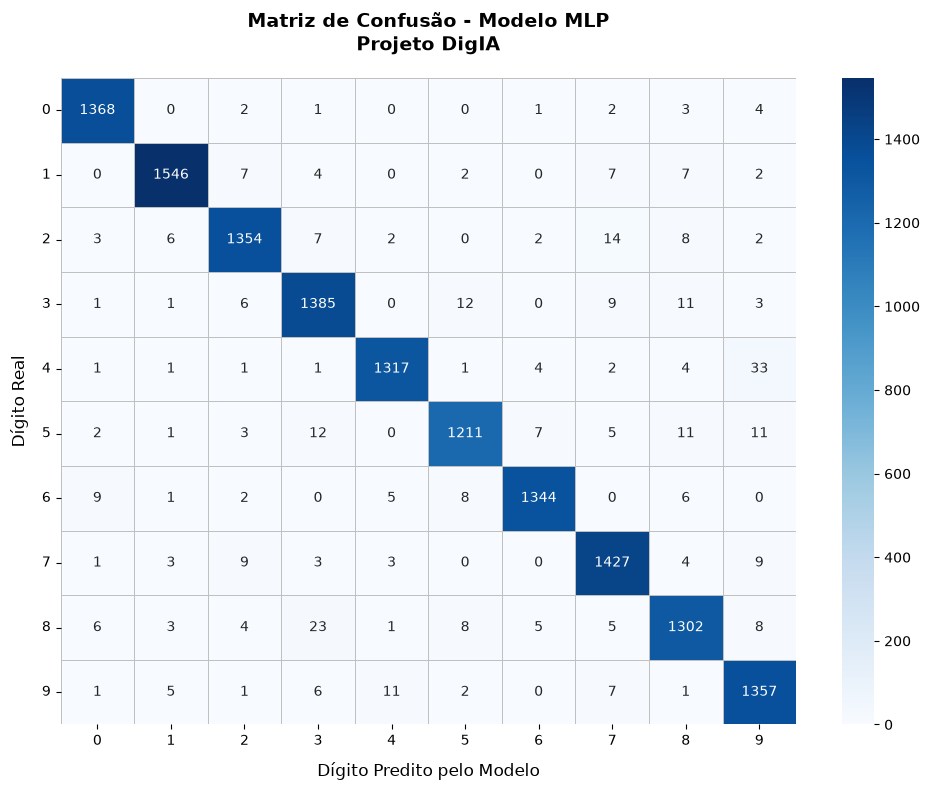

In [16]:
# chama a função de plotagem para todas as matrizes da lista
for m in matrizes:
    classificador_plotar = m['classificador']
    matriz_plotar = m['matriz_confusao']
    plota_matriz_confusao(matriz_plotar, classificador_plotar)

In [17]:
# Exibe tabela com os resultados / métricas dos 3 modelos.
pd.DataFrame(resultados_modelos)

,nome_modelo,acuracia,precision,recall,f1-score,tempo_treino
0,RandomForest,0.966857,0.966848,0.966857,0.966829,14.480455
1,MLP,0.972214,0.972325,0.972214,0.972226,75.294270
